# Synthetic Drift Detector Configuration and Evaluation

## Overview

This notebook selects and validates configurations for the three drift detectors used in the concept-drift forecasting pipeline:

- **ADWIN**
- **Page-Hinkley**
- **KSWIN**

The detectors are evaluated on synthetic data because the injected drift locations are known, allowing detector behaviour to be measured against ground-truth changepoints.

### Detector Input

The synthetic series is first passed through the **frozen Gradient Boosting forecasting model**. Drift detection is then performed on the resulting **absolute forecast-error stream**, rather than directly on the synthetic target series.

To provide a common and scale-consistent input to all three detectors, absolute forecast errors are normalized using statistics estimated from the **calibration period only**:

\[
z_t = \frac{|e_t|-\mu_{\mathrm{cal}}}{\sigma_{\mathrm{cal}}}
\]

where \(\mu_{\mathrm{cal}}\) and \(\sigma_{\mathrm{cal}}\) are the mean and standard deviation of the calibration-period absolute forecast errors. Test-period information is therefore not used to estimate the normalization parameters.

### Synthetic Drift Scenarios

Four synthetic scenarios are evaluated across five seeds (`1–5`):

- **None:** no injected drift; used as the negative control.
- **Sudden:** abrupt distributional change.
- **Gradual:** transition occurring over a drift interval.
- **Recurring:** distribution changes and subsequently returns.

### Configuration Selection

Detector configuration follows a common procedure:

1. **No-drift control:** candidate configurations are first evaluated on the `none` scenario. A configuration must produce **zero detections across all five no-drift seeds** before it is considered for selection.
2. **Drift evaluation:** passing configurations are evaluated on sudden, gradual, and recurring drift.
3. **Trade-off assessment:** configurations are compared using detection delay, false alarms per 10,000 observations, and missed detections.
4. **Configuration freeze:** one configuration is selected for each detector and used unchanged in the final comparison.

The purpose of tuning is not to force identical behaviour across detectors, but to select defensible configurations while preserving differences in their sensitivity, delay, false-alarm behaviour, and ability to detect different forms of drift.

### Final Evaluation

The frozen detector configurations are evaluated using the same synthetic scenarios, five-seed protocol, normalized forecast-error input, and evaluation function.

The final **T1 detector comparison** reports:

- **Detection delay — mean ± SD**
- **False alarms per 10,000 observations — mean ± SD**
- **Missed detections — mean ± SD**
- **Detector configuration**
- **Evaluation seeds**

This provides a reproducible comparison of ADWIN, Page-Hinkley, and KSWIN under a common experimental design.

In [9]:
import numpy as np
import pandas as pd

from drift_lab import detectors
from drift_lab.evaluation import evaluate_detections
from drift_lab.synthetic_generator import make_feature_series
from drift_lab.forecasters import (
    GradientBoostedForecaster,
    frozen_error_stream,
)

# Reproducible synthetic evaluation
SEEDS = [1, 2, 3, 4, 5]

# Synthetic scenarios used in T1
DRIFT_TYPES = ["none", "sudden", "gradual", "recurring"]

# Synthetic split
N_OBSERVATIONS = 20_000
TRAIN_END = 4_000
CALIBRATION_END = 5_000
TEST_START = 5_000

# Keep forecasting-model randomness fixed
FORECASTER_SEED = 0

# Common matching tolerance: 7 days × 48 half-hour observations
TOLERANCE = 48 * 7

## ADWIN — Configuration Selection

ADWIN is evaluated on the **calibration-normalized absolute forecast-error stream**, which is the common detector input used throughout the final experiment.

For each observation, the absolute forecast error is standardized using statistics estimated from the calibration period only:

\[
z_t = \frac{|e_t|-\mu_{\mathrm{cal}}}{\sigma_{\mathrm{cal}}}
\]

where \(\mu_{\mathrm{cal}}\) and \(\sigma_{\mathrm{cal}}\) are the mean and standard deviation of the calibration-period absolute errors. Using calibration statistics avoids test-data leakage and provides a scale-consistent input for comparison across ADWIN, Page-Hinkley, and KSWIN.

ADWIN's `delta` parameter controls its sensitivity to distributional change. Candidate values are evaluated across five synthetic seeds (`1–5`).

Configuration selection follows two stages:

1. **No-drift control:** the configuration must produce zero detections across all five no-drift seeds.
2. **Drift evaluation:** passing configurations are compared on sudden, gradual, and recurring drift using detection delay, false alarms per 10,000 observations, and missed detections.

The selected ADWIN configuration is then frozen for the final T1 detector comparison.

In [10]:
def build_normalized_absolute_error_stream(drift_type, seed):
    """
    Build the calibration-normalized absolute forecast-error stream
    used as the common detector input.

    Returns
    -------
    stream : np.ndarray
        Normalized absolute forecast-error stream for the test period.

    truth : list[int]
        Ground-truth changepoints relative to the test stream.

    cal_mean : float
        Mean absolute calibration error.

    cal_std : float
        Standard deviation of absolute calibration error.
    """

    data, full_truth = make_feature_series(
        kind=drift_type,
        n=N_OBSERVATIONS,
        seed=seed,
    )

    train = data.iloc[:TRAIN_END].copy()

    calibration = data.iloc[
        TRAIN_END:CALIBRATION_END
    ].copy()

    test = data.iloc[
        TEST_START:
    ].copy()

    model = GradientBoostedForecaster(
        feature_mode="calendar+lags",
        lags=(48, 336),
        seed=FORECASTER_SEED,
    )

    model.fit(train)

    calibration_errors = frozen_error_stream(
        model,
        calibration,
        history_df=train,
    )

    calibration_abs = (
        calibration_errors["error"]
        .abs()
        .to_numpy(dtype=float)
    )

    cal_mean = calibration_abs.mean()
    cal_std = calibration_abs.std()

    test_errors = frozen_error_stream(
        model,
        test,
        history_df=calibration,
    )

    test_abs = (
        test_errors["error"]
        .abs()
        .to_numpy(dtype=float)
    )

    stream = (
        test_abs - cal_mean
    ) / cal_std

    truth = [
        int(cp - TEST_START)
        for cp in full_truth
    ]

    return stream, truth, cal_mean, cal_std

In [11]:
ADWIN_DELTAS = [
    0.0001,
    0.0002,
    0.0005,
    0.001,
    0.002,
]

adwin_none_results = []

for delta in ADWIN_DELTAS:
    for seed in SEEDS:

        stream, _, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="none",
                seed=seed,
            )
        )

        detections = detectors.run_adwin(
            stream,
            delta=delta,
        )

        adwin_none_results.append({
            "delta": delta,
            "seed": seed,
            "n_detections": len(detections),
        })

adwin_none_summary = (
    pd.DataFrame(adwin_none_results)
    .groupby("delta")
    .agg(
        total_detections=("n_detections", "sum"),
        seeds_with_detections=(
            "n_detections",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
)

adwin_none_summary

,delta,total_detections,seeds_with_detections
0,0.0001,0,0
1,0.0002,0,0
2,0.0005,0,0
3,0.0010,0,0
4,0.0020,0,0


In [12]:
adwin_tuning_results = []

for delta in ADWIN_DELTAS:
    for drift_type in ["sudden", "gradual", "recurring"]:
        for seed in SEEDS:

            stream, truth, _, _ = (
                build_normalized_absolute_error_stream(
                    drift_type=drift_type,
                    seed=seed,
                )
            )

            detections = detectors.run_adwin(
                stream,
                delta=delta,
            )

            metrics = evaluate_detections(
                detected_changepoints=detections,
                true_changepoints=truth,
                n_observations=len(stream),
                drift_type=drift_type,
                tolerance=TOLERANCE,
            )

            adwin_tuning_results.append({
                "delta": delta,
                "drift_type": drift_type,
                "seed": seed,
                "detection_delay": metrics["detection_delay"],
                "false_alarms_per_10k":
                    metrics["false_alarms_per_10000"],
                "missed": metrics["missed_detections"],
            })

adwin_tuning_df = pd.DataFrame(adwin_tuning_results)

In [13]:
adwin_tuning_summary = (
    adwin_tuning_df
    .groupby(["delta", "drift_type"])
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        missed_total=("missed", "sum"),
    )
    .reset_index()
)

# Display small delta values clearly
adwin_tuning_summary["delta"] = (
    adwin_tuning_summary["delta"]
    .map(lambda x: f"{x:.4f}")
)

adwin_tuning_summary.round(3)

,delta,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,missed_total
0,0.0001,gradual,600.6,114.039,0.933,0
1,0.0001,recurring,29.4,8.764,1.333,0
2,0.0001,sudden,23.0,0.000,1.333,0
3,0.0002,gradual,600.6,114.039,1.067,0
4,0.0002,recurring,29.4,8.764,1.333,0
5,0.0002,sudden,23.0,0.000,1.333,0
6,0.0005,gradual,587.8,105.163,1.067,0
7,0.0005,recurring,26.2,7.155,1.600,0
8,0.0005,sudden,23.0,0.000,1.333,0
9,0.0010,gradual,575.0,117.576,1.067,0


### ADWIN Configuration Selection

All tested ADWIN `delta` values passed the no-drift control, with zero detections across all five no-drift seeds.

The drift-scenario comparison showed a clear trade-off. Larger `delta` values slightly reduced delay for gradual and recurring drift, but generally increased false-alarm rates. Sudden-drift delay remained essentially unchanged across the tested settings, and no drift events were missed under any configuration.

`delta = 0.0001` was selected because it provided the strongest overall false-alarm control while retaining complete drift detection:

- **Sudden drift:** 23.0 mean delay, 1.33 false alarms per 10k, 0 missed.
- **Gradual drift:** 600.6 mean delay, 0.93 false alarms per 10k, 0 missed.
- **Recurring drift:** 29.4 mean delay, 1.33 false alarms per 10k, 0 missed.
- **No drift:** zero detections across all five seeds.

The final ADWIN configuration is therefore:

`delta = 0.0001`

In [14]:
ADWIN_FINAL_CONFIG = {
    "delta": 0.0001,
}

adwin_final_results = []

for drift_type in [
    "none",
    "sudden",
    "gradual",
    "recurring",
]:
    for seed in SEEDS:

        stream, truth, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type=drift_type,
                seed=seed,
            )
        )

        detections = detectors.run_adwin(
            stream,
            **ADWIN_FINAL_CONFIG,
        )

        metrics = evaluate_detections(
            detected_changepoints=detections,
            true_changepoints=truth,
            n_observations=len(stream),
            drift_type=drift_type,
            tolerance=TOLERANCE,
        )

        adwin_final_results.append({
            "drift_type": drift_type,
            "seed": seed,
            "detection_delay":
                metrics["detection_delay"],
            "false_alarms_per_10k":
                metrics["false_alarms_per_10000"],
            "missed":
                metrics["missed_detections"],
            "n_detections":
                len(detections),
        })

adwin_final_df = pd.DataFrame(
    adwin_final_results
)

adwin_final_summary = (
    adwin_final_df
    .groupby("drift_type")
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        false_alarms_per_10k_sd=(
            "false_alarms_per_10k",
            "std",
        ),
        missed_total=("missed", "sum"),
        detections_total=("n_detections", "sum"),
    )
    .reset_index()
)

adwin_final_summary.round(3)

,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,false_alarms_per_10k_sd,missed_total,detections_total
0,gradual,600.6,114.039,0.933,0.76,0,12
1,none,NaN,NaN,0.000,0.00,0,0
2,recurring,29.4,8.764,1.333,0.00,0,20
3,sudden,23.0,0.000,1.333,0.00,0,15


In [15]:
import matplotlib.pyplot as plt


def plot_detector_evaluation(
    detector_name,
    detector_func,
    detector_config,
    seed=1,
):
    """
    Plot one representative synthetic evaluation seed for:

    - none
    - sudden
    - gradual
    - recurring

    Colours
    -------
    Blue   : normalized absolute forecast-error stream
    Red    : true changepoint / gradual drift window
    Green  : matched detector alarm
    Orange : unmatched detector alarm
    """

    drift_types = [
        "none",
        "sudden",
        "gradual",
        "recurring",
    ]

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(15, 14),
        sharex=False,
    )

    for ax, drift_type in zip(
        axes,
        drift_types,
    ):

        # ---------------------------------------------
        # Build detector input
        # ---------------------------------------------
        stream, truth, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type=drift_type,
                seed=seed,
            )
        )

        # ---------------------------------------------
        # Run detector
        # ---------------------------------------------
        detections = detector_func(
            stream,
            **detector_config,
        )

        # ---------------------------------------------
        # Shared evaluation
        # ---------------------------------------------
        metrics = evaluate_detections(
            detected_changepoints=detections,
            true_changepoints=truth,
            n_observations=len(stream),
            drift_type=drift_type,
            tolerance=TOLERANCE,
        )

        matched_pairs = metrics["matched_pairs"]

        false_alarm_indices = metrics[
            "false_alarm_indices"
        ]

        # ---------------------------------------------
        # Detector input stream
        # ---------------------------------------------
        ax.plot(
            stream,
            color="steelblue",
            linewidth=0.7,
            alpha=0.8,
            label="Normalized absolute forecast error",
        )

        # ---------------------------------------------
        # Ground truth
        # ---------------------------------------------
        if drift_type == "gradual":

            drift_start = truth[0]
            drift_end = truth[1]

            ax.axvspan(
                drift_start,
                drift_end,
                color="red",
                alpha=0.12,
                label="True gradual drift window",
            )

            ax.axvline(
                drift_start,
                color="red",
                linestyle="--",
                linewidth=1.5,
            )

            ax.axvline(
                drift_end,
                color="red",
                linestyle="--",
                linewidth=1.5,
            )

        else:

            for i, true_cp in enumerate(truth):

                ax.axvline(
                    true_cp,
                    color="red",
                    linestyle="--",
                    linewidth=1.8,
                    label=(
                        "True changepoint"
                        if i == 0
                        else None
                    ),
                )

        # ---------------------------------------------
        # Matched detections
        # ---------------------------------------------
        for i, match in enumerate(matched_pairs):

            detected_cp = int(
                match["detected"]
            )

            # Gradual has different match structure
            if drift_type == "gradual":

                true_reference = int(
                    match["true_start"]
                )

            else:

                true_reference = int(
                    match["true"]
                )

            delay = (
                detected_cp
                - true_reference
            )

            ax.axvline(
                detected_cp,
                color="green",
                linewidth=2,
                label=(
                    "Matched detection"
                    if i == 0
                    else None
                ),
            )

            y_min, y_max = ax.get_ylim()

            y_position = (
                y_min
                + 0.82 * (y_max - y_min)
            )

            ax.text(
                detected_cp,
                y_position,
                f"delay={delay}",
                color="green",
                rotation=90,
                fontsize=9,
                verticalalignment="top",
                horizontalalignment="right",
            )

        # ---------------------------------------------
        # Unmatched detections
        # ---------------------------------------------
        for i, detected_cp in enumerate(
            false_alarm_indices
        ):

            ax.axvline(
                int(detected_cp),
                color="orange",
                linestyle=":",
                linewidth=1.5,
                label=(
                    "Unmatched detection"
                    if i == 0
                    else None
                ),
            )

        # ---------------------------------------------
        # Evaluation summary
        # ---------------------------------------------
        detection_delay = metrics[
            "detection_delay"
        ]

        if np.isnan(detection_delay):
            delay_text = "—"
        else:
            delay_text = (
                f"{detection_delay:.1f}"
            )

        false_alarm_rate = metrics[
            "false_alarms_per_10000"
        ]

        missed = metrics[
            "missed_detections"
        ]

        ax.set_title(
            f"{drift_type.capitalize()} drift"
            f"  |  delay = {delay_text}"
            f"  |  false alarms / 10k = "
            f"{false_alarm_rate:.2f}"
            f"  |  missed = {missed}"
        )

        ax.set_ylabel(
            "Normalized\nabsolute error"
        )

        ax.legend(
            loc="upper right",
            fontsize=8,
        )

        ax.grid(
            alpha=0.15
        )

    axes[-1].set_xlabel(
        "Test observation index"
    )

    fig.suptitle(
        f"{detector_name} — Synthetic Drift Detection Evaluation "
        f"(Seed {seed})",
        fontsize=16,
        y=1.01,
    )

    plt.tight_layout()
    plt.show()

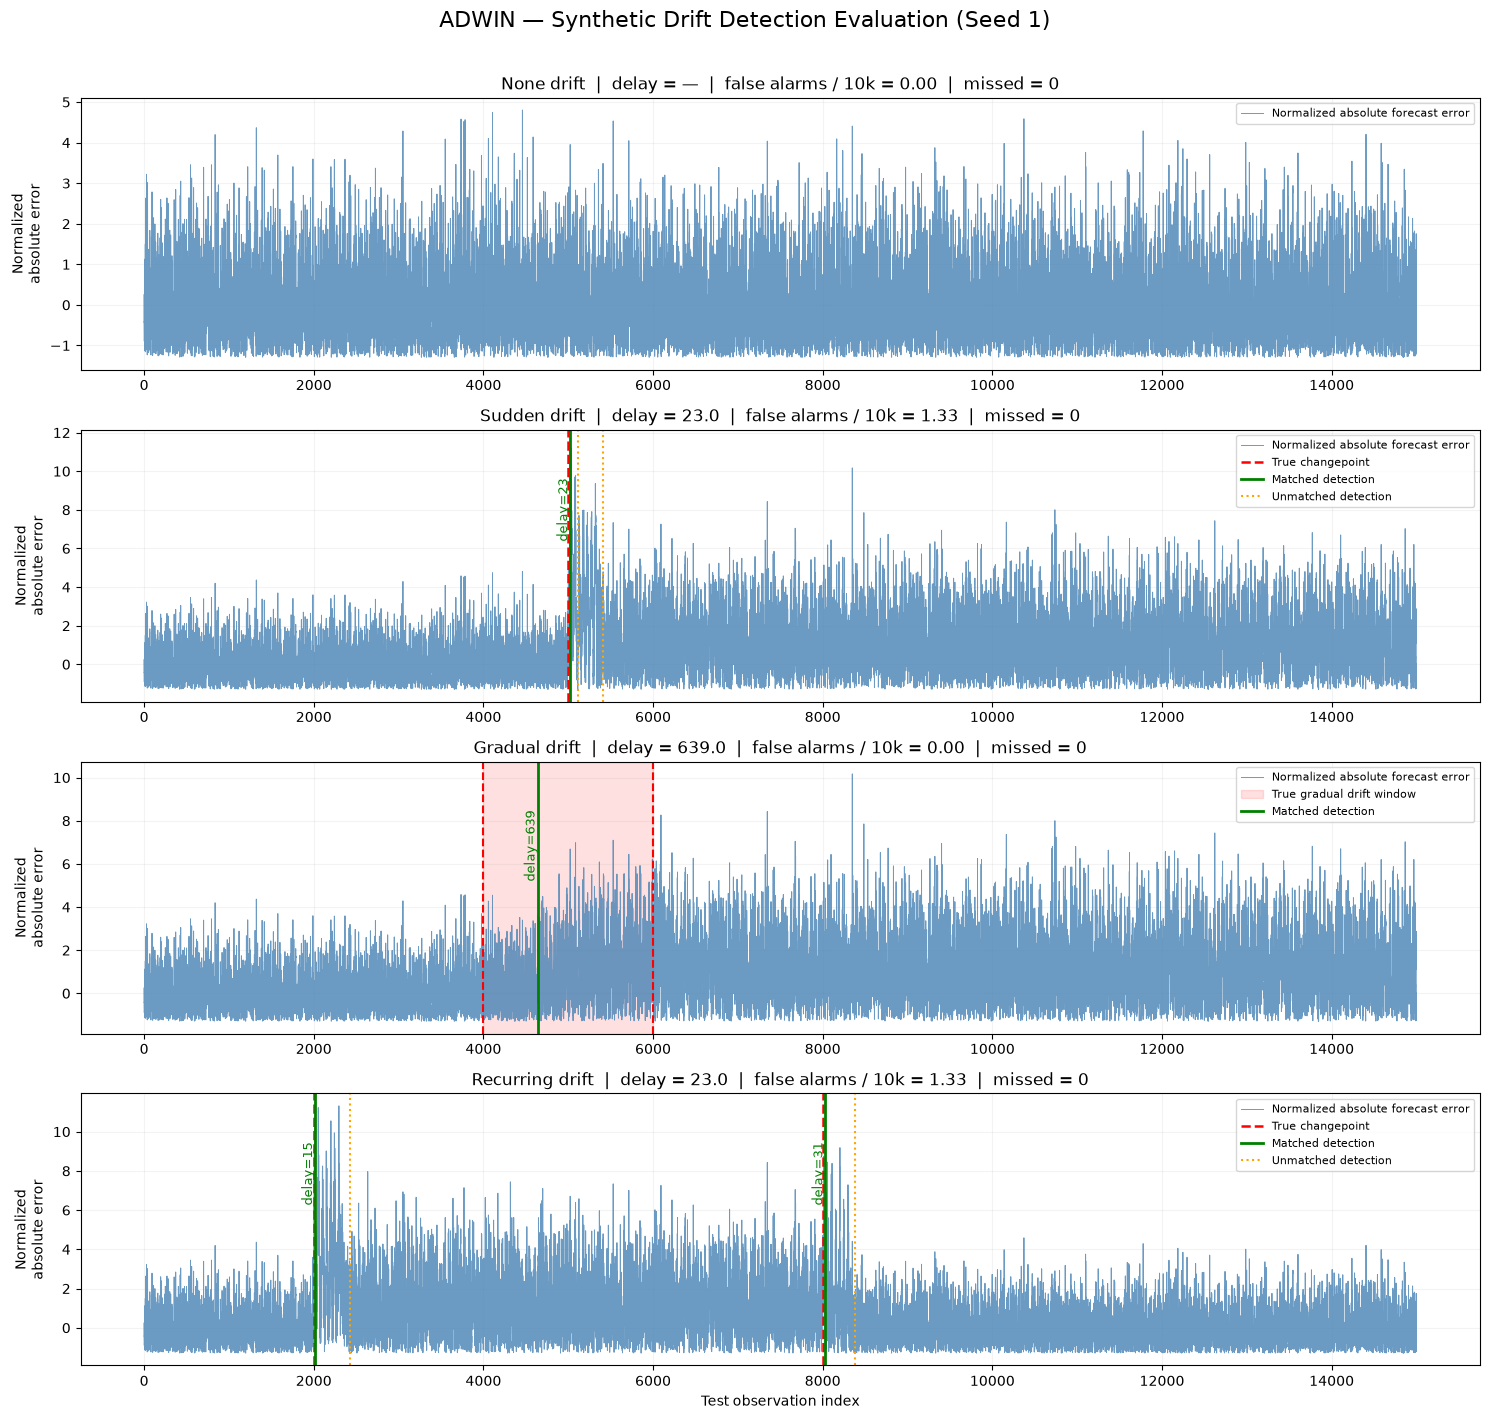

In [16]:
plot_detector_evaluation(
    detector_name="ADWIN",
    detector_func=detectors.run_adwin,
    detector_config={
        "delta": 0.0001,
    },
    seed=1,
)

_______________________________________________

## Page-Hinkley — Configuration Selection

Page-Hinkley is evaluated on the same **calibration-normalized absolute forecast-error stream** used for ADWIN so that detector comparisons are based on identical input preprocessing.

The initial Page-Hinkley configuration was highly sensitive to the raw error scale and produced many detections in the no-drift control. After normalization, configuration selection focused on finding the least conservative settings that still satisfied the required clean no-drift behaviour.

The tuning process considers:

- `threshold`: the amount of accumulated evidence required before declaring drift.
- `delta`: the tolerated change before evidence accumulates.
- `alpha`: the weighting applied to historical observations.
- `min_instances`: the minimum number of observations before detection is allowed.

Configuration selection follows the same rule used for ADWIN:

1. **No-drift gate:** zero detections across all five no-drift seeds.
2. **Drift evaluation:** passing configurations are compared on sudden, gradual, and recurring drift.
3. **Trade-off assessment:** detection delay, false alarms per 10,000 observations, and missed detections are considered together.

The final Page-Hinkley configuration is then frozen for the T1 comparison.

In [25]:
PH_THRESHOLDS = [
    50,
    100,
    200,
    300,
    400,
    500,
    700,
]

ph_threshold_none_results = []

for threshold in PH_THRESHOLDS:
    for seed in SEEDS:

        stream, _, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="none",
                seed=seed,
            )
        )

        detections = detectors.run_page_hinkley(
            stream,
            threshold=threshold,
            delta=0.005,
            alpha=0.9999,
            min_instances=30,
        )

        ph_threshold_none_results.append({
            "threshold": threshold,
            "seed": seed,
            "n_detections": len(detections),
        })

ph_threshold_none_summary = (
    pd.DataFrame(ph_threshold_none_results)
    .groupby("threshold")
    .agg(
        total_detections=("n_detections", "sum"),
        seeds_with_detections=(
            "n_detections",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
)

ph_threshold_none_summary

,threshold,total_detections,seeds_with_detections
0,50,46,5
1,100,6,4
2,200,1,1
3,300,0,0
4,400,0,0
5,500,0,0
6,700,0,0


In [26]:
PH_PASSING_THRESHOLDS = [
    300,
    400,
    500,
    700,
]

ph_threshold_tuning_results = []

for threshold in PH_PASSING_THRESHOLDS:
    for drift_type in ["sudden", "gradual", "recurring"]:
        for seed in SEEDS:

            stream, truth, _, _ = (
                build_normalized_absolute_error_stream(
                    drift_type=drift_type,
                    seed=seed,
                )
            )

            detections = detectors.run_page_hinkley(
                stream,
                threshold=threshold,
                delta=0.005,
                alpha=0.9999,
                min_instances=30,
            )

            metrics = evaluate_detections(
                detected_changepoints=detections,
                true_changepoints=truth,
                n_observations=len(stream),
                drift_type=drift_type,
                tolerance=TOLERANCE,
            )

            ph_threshold_tuning_results.append({
                "threshold": threshold,
                "drift_type": drift_type,
                "seed": seed,
                "detection_delay": metrics["detection_delay"],
                "false_alarms_per_10k":
                    metrics["false_alarms_per_10000"],
                "missed": metrics["missed_detections"],
            })

ph_threshold_tuning_df = pd.DataFrame(
    ph_threshold_tuning_results
)

In [27]:
ph_threshold_summary = (
    ph_threshold_tuning_df
    .groupby([
        "threshold",
        "drift_type",
    ])
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        missed_total=("missed", "sum"),
    )
    .reset_index()
)

ph_threshold_summary.round(3)

,threshold,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,missed_total
0,300,gradual,852.4,107.603,0.800,0
1,300,recurring,56.1,12.106,1.333,4
2,300,sudden,51.2,13.065,0.933,0
3,400,gradual,972.0,92.469,0.533,0
4,400,recurring,90.0,40.957,1.200,4
5,400,sudden,76.4,7.232,0.800,0
6,500,gradual,1088.2,86.757,0.267,0
7,500,recurring,110.4,9.940,1.333,5
8,500,sudden,107.2,20.030,0.667,0
9,700,gradual,1289.6,92.441,0.133,0


## Fine threshold search around the no-drift boundary

In [28]:
PH_FINE_THRESHOLDS = [
    201, 202, 203, 204, 205,
    206, 207, 208, 209, 210,
]

ph_fine_none_results = []

for threshold in PH_FINE_THRESHOLDS:
    for seed in SEEDS:

        stream, _, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="none",
                seed=seed,
            )
        )

        detections = detectors.run_page_hinkley(
            stream,
            threshold=threshold,
            delta=0.005,
            alpha=0.9999,
            min_instances=30,
        )

        ph_fine_none_results.append({
            "threshold": threshold,
            "seed": seed,
            "n_detections": len(detections),
        })

ph_fine_none_summary = (
    pd.DataFrame(ph_fine_none_results)
    .groupby("threshold")
    .agg(
        total_detections=("n_detections", "sum"),
        seeds_with_detections=(
            "n_detections",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
)

ph_fine_none_summary

,threshold,total_detections,seeds_with_detections
0,201,1,1
1,202,1,1
2,203,1,1
3,204,1,1
4,205,1,1
5,206,1,1
6,207,1,1
7,208,1,1
8,209,0,0
9,210,0,0


In [29]:
PH_THRESHOLD = 209

ph_threshold_209_results = []

for drift_type in ["sudden", "gradual", "recurring"]:
    for seed in SEEDS:

        stream, truth, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type=drift_type,
                seed=seed,
            )
        )

        detections = detectors.run_page_hinkley(
            stream,
            threshold=PH_THRESHOLD,
            delta=0.005,
            alpha=0.9999,
            min_instances=30,
        )

        metrics = evaluate_detections(
            detected_changepoints=detections,
            true_changepoints=truth,
            n_observations=len(stream),
            drift_type=drift_type,
            tolerance=TOLERANCE,
        )

        ph_threshold_209_results.append({
            "drift_type": drift_type,
            "seed": seed,
            "detection_delay": metrics["detection_delay"],
            "false_alarms_per_10k":
                metrics["false_alarms_per_10000"],
            "missed": metrics["missed_detections"],
            "n_detections": len(detections),
        })

ph_threshold_209_df = pd.DataFrame(
    ph_threshold_209_results
)

ph_threshold_209_summary = (
    ph_threshold_209_df
    .groupby("drift_type")
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        missed_total=("missed", "sum"),
        detections_total=("n_detections", "sum"),
    )
    .reset_index()
)

ph_threshold_209_summary.round(3)

,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,missed_total,detections_total
0,gradual,704.4,88.732,2.000,0,20
1,recurring,49.2,21.394,1.333,1,19
2,sudden,34.0,5.244,1.467,0,16


## Page-Hinkley alpha sweep

In [30]:
PH_ALPHAS = [
    0.99,
    0.995,
    0.999,
    0.9995,
    0.9999,
]

ph_alpha_results = []

for alpha in PH_ALPHAS:
    for drift_type in [
        "none",
        "sudden",
        "gradual",
        "recurring",
    ]:
        for seed in SEEDS:

            stream, truth, _, _ = (
                build_normalized_absolute_error_stream(
                    drift_type=drift_type,
                    seed=seed,
                )
            )

            detections = detectors.run_page_hinkley(
                stream,
                threshold=209,
                delta=0.005,
                alpha=alpha,
                min_instances=30,
            )

            metrics = evaluate_detections(
                detected_changepoints=detections,
                true_changepoints=truth,
                n_observations=len(stream),
                drift_type=drift_type,
                tolerance=TOLERANCE,
            )

            ph_alpha_results.append({
                "alpha": alpha,
                "drift_type": drift_type,
                "seed": seed,
                "detection_delay":
                    metrics["detection_delay"],
                "false_alarms_per_10k":
                    metrics["false_alarms_per_10000"],
                "missed":
                    metrics["missed_detections"],
                "n_detections":
                    len(detections),
            })

ph_alpha_df = pd.DataFrame(ph_alpha_results)

ph_alpha_summary = (
    ph_alpha_df
    .groupby(["alpha", "drift_type"])
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        missed_total=("missed", "sum"),
        detections_total=("n_detections", "sum"),
    )
    .reset_index()
)

ph_alpha_summary.round(3)

,alpha,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,missed_total,detections_total
0,0.990,gradual,NaN,NaN,0.000,5,0
1,0.990,none,NaN,NaN,0.000,0,0
2,0.990,recurring,41.5,11.358,0.400,3,10
3,0.990,sudden,42.6,1.673,0.133,0,6
4,0.995,gradual,1143.6,133.180,0.000,0,5
5,0.995,none,NaN,NaN,0.000,0,0
6,0.995,recurring,41.6,14.843,1.200,4,15
7,0.995,sudden,39.0,1.225,0.667,0,10
8,0.999,gradual,765.6,89.366,1.067,0,13
9,0.999,none,NaN,NaN,0.000,0,0


### Page-Hinkley Alpha Selection

All tested `alpha` values maintained a clean no-drift control, but their behaviour on the drift scenarios differed substantially.

Lower values were too conservative for some drift types. In particular, `alpha = 0.99` missed all gradual-drift events, while `alpha = 0.995` produced a long gradual-drift delay and missed four recurring events.

Increasing `alpha` improved sensitivity, but values above `0.999` also increased false alarms. `alpha = 0.999` provided the most balanced behaviour:

- **Sudden:** delay = 35.4, false alarms = 0.93/10k, 0 missed.
- **Gradual:** delay = 765.6, false alarms = 1.07/10k, 0 missed.
- **Recurring:** delay = 73.5, false alarms = 1.20/10k, 1 missed.
- **None:** zero detections across all five seeds.

Therefore, `alpha = 0.999` is retained while the remaining Page-Hinkley parameters are examined.

In [31]:
PH_DELTAS = [
    0.0,
    0.001,
    0.0025,
    0.005,
    0.01,
    0.02,
]

ph_delta_none_results = []

for delta in PH_DELTAS:
    for seed in SEEDS:

        stream, _, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="none",
                seed=seed,
            )
        )

        detections = detectors.run_page_hinkley(
            stream,
            threshold=209,
            delta=delta,
            alpha=0.999,
            min_instances=30,
        )

        ph_delta_none_results.append({
            "delta": delta,
            "seed": seed,
            "n_detections": len(detections),
        })

ph_delta_none_summary = (
    pd.DataFrame(ph_delta_none_results)
    .groupby("delta")
    .agg(
        total_detections=("n_detections", "sum"),
        seeds_with_detections=(
            "n_detections",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
)

ph_delta_none_summary

,delta,total_detections,seeds_with_detections
0,0.0000,0,0
1,0.0010,0,0
2,0.0025,0,0
3,0.0050,0,0
4,0.0100,0,0
5,0.0200,0,0


In [32]:
ph_delta_results = []

for delta in PH_DELTAS:
    for drift_type in [
        "sudden",
        "gradual",
        "recurring",
    ]:
        for seed in SEEDS:

            stream, truth, _, _ = (
                build_normalized_absolute_error_stream(
                    drift_type=drift_type,
                    seed=seed,
                )
            )

            detections = detectors.run_page_hinkley(
                stream,
                threshold=209,
                delta=delta,
                alpha=0.999,
                min_instances=30,
            )

            metrics = evaluate_detections(
                detected_changepoints=detections,
                true_changepoints=truth,
                n_observations=len(stream),
                drift_type=drift_type,
                tolerance=TOLERANCE,
            )

            ph_delta_results.append({
                "delta": delta,
                "drift_type": drift_type,
                "seed": seed,
                "detection_delay":
                    metrics["detection_delay"],
                "false_alarms_per_10k":
                    metrics["false_alarms_per_10000"],
                "missed":
                    metrics["missed_detections"],
                "n_detections":
                    len(detections),
            })

ph_delta_df = pd.DataFrame(
    ph_delta_results
)

ph_delta_summary = (
    ph_delta_df
    .groupby(["delta", "drift_type"])
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        missed_total=("missed", "sum"),
        detections_total=(
            "n_detections",
            "sum",
        ),
    )
    .reset_index()
)

ph_delta_summary.round(3)

,delta,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,missed_total,detections_total
0,0.000,gradual,764.4,87.996,1.067,0,13
1,0.000,recurring,73.5,57.680,1.200,1,18
2,0.000,sudden,35.2,3.564,0.933,0,12
3,0.001,gradual,765.2,88.903,1.067,0,13
4,0.001,recurring,73.5,57.680,1.200,1,18
5,0.001,sudden,35.4,3.507,0.933,0,12
6,0.002,gradual,765.2,88.903,1.067,0,13
7,0.002,recurring,73.5,57.680,1.200,1,18
8,0.002,sudden,35.4,3.507,0.933,0,12
9,0.005,gradual,765.6,89.366,1.067,0,13


### Page-Hinkley Delta Sensitivity

All tested `delta` values (`0–0.02`) passed the no-drift control and produced nearly identical behaviour across the drift scenarios.

False-alarm rates and missed detections remained unchanged across almost the entire tested range, while detection-delay differences were negligible. For example, gradual-drift mean delay varied only from 764.4 observations at `delta = 0` to 768.8 at `delta = 0.02`.

This indicates that Page-Hinkley performance under the current normalized error stream is substantially more sensitive to `threshold` and `alpha` than to `delta`.

Therefore, `delta = 0.005` is retained as the fixed configuration value rather than being interpreted as an empirically optimal setting.

Current Page-Hinkley candidate:

- `threshold = 209`
- `alpha = 0.999`
- `delta = 0.005`
- `min_instances = 30`

In [33]:
PAGE_HINKLEY_FINAL_CONFIG = {
    "threshold": 209,
    "delta": 0.005,
    "alpha": 0.999,
    "min_instances": 30,
}

page_hinkley_final_results = []

for drift_type in [
    "none",
    "sudden",
    "gradual",
    "recurring",
]:
    for seed in SEEDS:

        stream, truth, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type=drift_type,
                seed=seed,
            )
        )

        detections = detectors.run_page_hinkley(
            stream,
            **PAGE_HINKLEY_FINAL_CONFIG,
        )

        metrics = evaluate_detections(
            detected_changepoints=detections,
            true_changepoints=truth,
            n_observations=len(stream),
            drift_type=drift_type,
            tolerance=TOLERANCE,
        )

        page_hinkley_final_results.append({
            "drift_type": drift_type,
            "seed": seed,
            "detection_delay":
                metrics["detection_delay"],
            "false_alarms_per_10k":
                metrics["false_alarms_per_10000"],
            "missed":
                metrics["missed_detections"],
            "n_detections":
                len(detections),
        })

page_hinkley_final_df = pd.DataFrame(
    page_hinkley_final_results
)

page_hinkley_final_summary = (
    page_hinkley_final_df
    .groupby("drift_type")
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        false_alarms_per_10k_sd=(
            "false_alarms_per_10k",
            "std",
        ),
        missed_total=("missed", "sum"),
        detections_total=(
            "n_detections",
            "sum",
        ),
    )
    .reset_index()
)

page_hinkley_final_summary.round(3)

,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,false_alarms_per_10k_sd,missed_total,detections_total
0,gradual,765.6,89.366,1.067,0.365,0,13
1,none,NaN,NaN,0.000,0.000,0,0
2,recurring,73.5,57.680,1.200,0.298,1,18
3,sudden,35.4,3.507,0.933,0.365,0,12


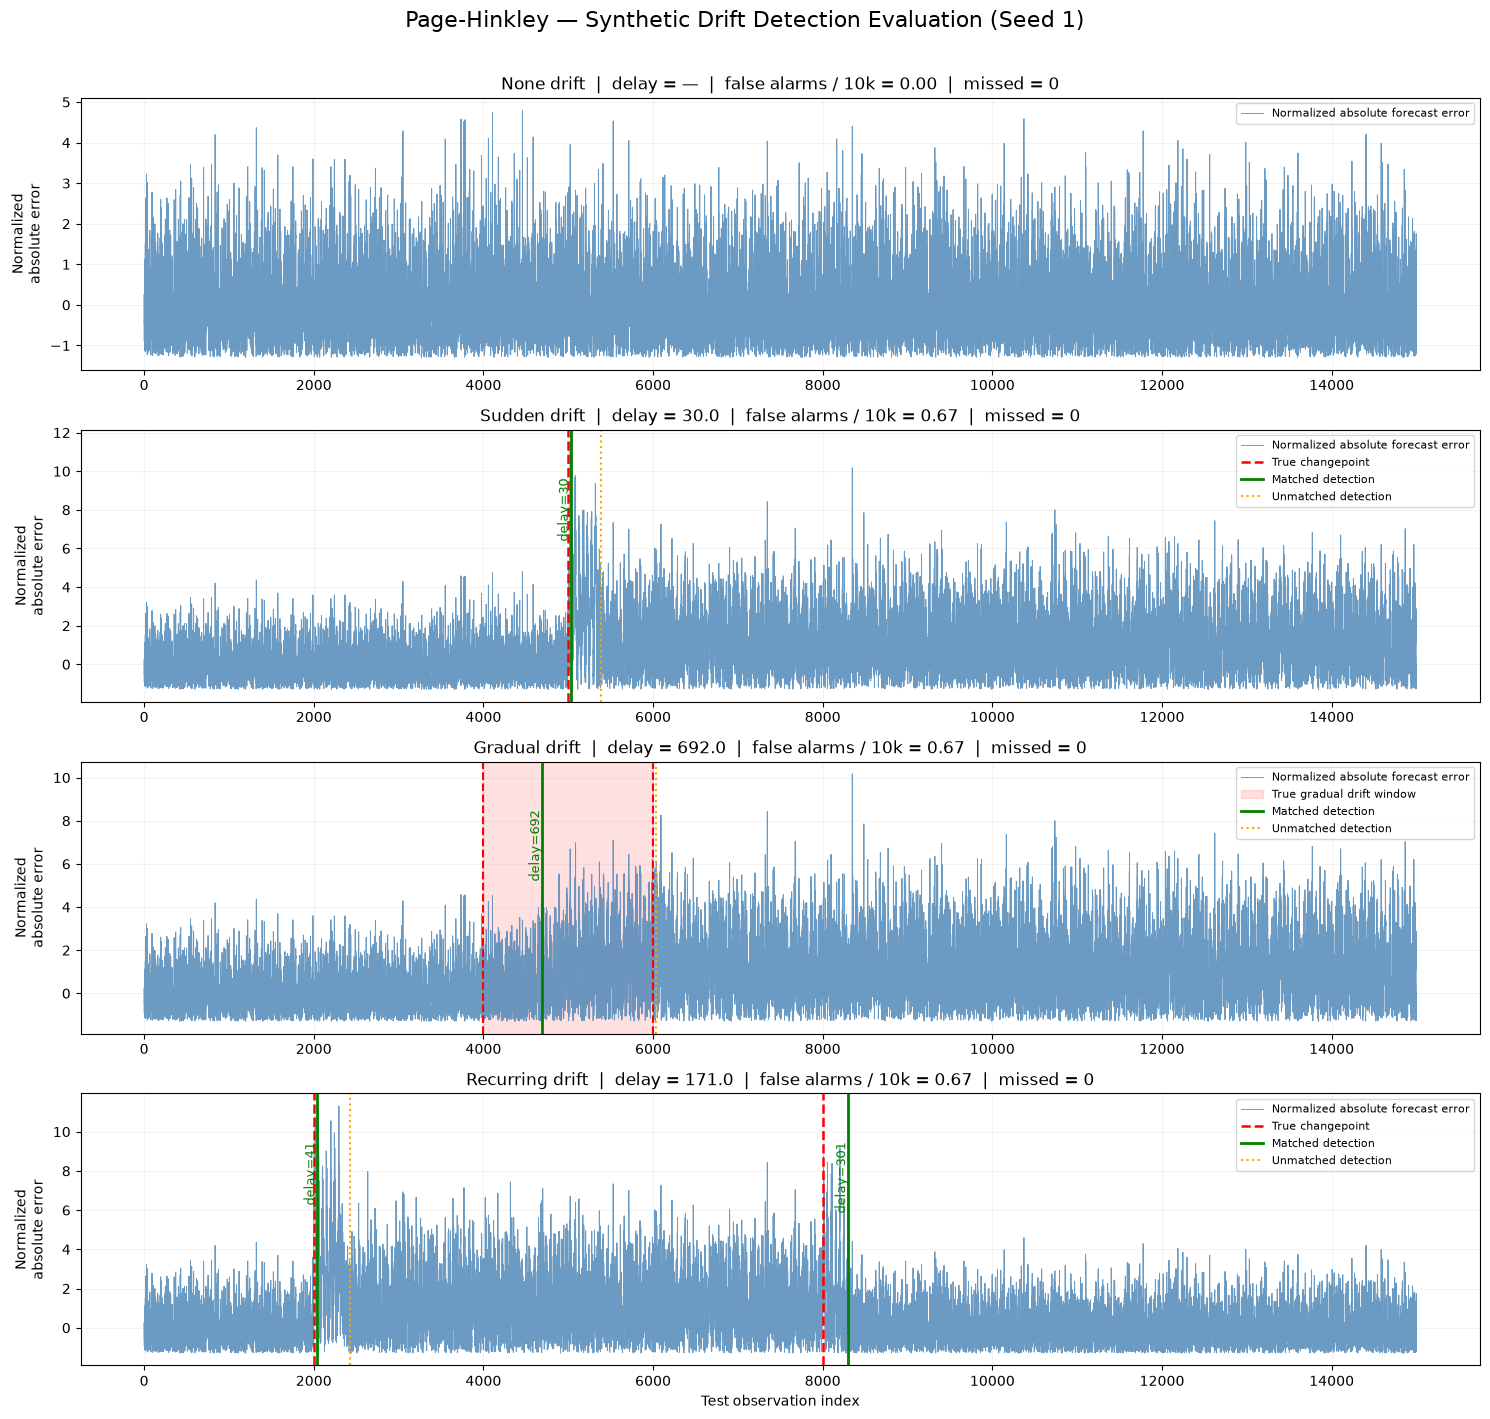

In [34]:
plot_detector_evaluation(
    detector_name="Page-Hinkley",
    detector_func=detectors.run_page_hinkley,
    detector_config={
        "threshold": 209,
        "delta": 0.005,
        "alpha": 0.999,
        "min_instances": 30,
    },
    seed=1,
)

______________________________________________

## KSWIN — Configuration Selection

KSWIN is evaluated using the same **calibration-normalized absolute forecast-error stream**, synthetic scenarios, five seeds, and shared evaluation function used for ADWIN and Page-Hinkley.

KSWIN compares the distribution of a recent sample against a reference sample using a Kolmogorov–Smirnov test. Its main tuning parameters are:

- `alpha`: significance threshold controlling how strong the evidence must be before drift is signalled.
- `window_size`: number of recent observations maintained by the detector.
- `stat_size`: size of the most recent sample used in the KS comparison.
- `seed` — controls KSWIN's internal sampling and is fixed for reproducibility.

Configuration selection follows the same no-drift-first procedure:

1. Candidate settings are first tested on the **no-drift scenario**.
2. Any configuration producing a no-drift detection is rejected.
3. Passing configurations are then evaluated on sudden, gradual, and recurring drift.
4. Detection delay, false alarms per 10,000 observations, and missed detections are considered together.
5. One final KSWIN configuration is frozen for the T1 comparison.

Because KSWIN showed a strong interaction between `alpha`, `window_size`, and `stat_size`, tuning focuses first on satisfying the clean no-drift control and then on balancing drift sensitivity against false alarms.

## Initial alpha no-drift sweep

In [35]:
KSWIN_ALPHAS = [
    0.001,
    0.0005,
    0.00025,
    0.0001,
    0.00005,
]

KSWIN_WINDOW_SIZE = 100
KSWIN_STAT_SIZE = 50
KSWIN_SEED = 12

kswin_alpha_none_results = []

for alpha in KSWIN_ALPHAS:
    for seed in SEEDS:

        stream, _, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="none",
                seed=seed,
            )
        )

        detections = detectors.run_kswin(
            stream,
            alpha=alpha,
            window_size=KSWIN_WINDOW_SIZE,
            stat_size=KSWIN_STAT_SIZE,
            seed=KSWIN_SEED,
        )

        kswin_alpha_none_results.append({
            "alpha": alpha,
            "seed": seed,
            "n_detections": len(detections),
        })

kswin_alpha_none_summary = (
    pd.DataFrame(kswin_alpha_none_results)
    .groupby("alpha")
    .agg(
        total_detections=("n_detections", "sum"),
        seeds_with_detections=(
            "n_detections",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
    .sort_values("alpha")
)

# Prevent scientific values from being rounded away
kswin_alpha_none_summary.style.format({
    "alpha": "{:.5f}"
})

,alpha,total_detections,seeds_with_detections
0,0.00005,0,0
1,0.00010,0,0
2,0.00025,3,2
3,0.00050,3,2
4,0.00100,5,4


## Window/stat-size no-drift grid

In [36]:
KSWIN_WINDOW_GRID = [
    (70, 35),
    (80, 40),
    (90, 45),
    (100, 50),
    (110, 55),
    (120, 60),
    (140, 70),
]

kswin_window_none_results = []

for window_size, stat_size in KSWIN_WINDOW_GRID:
    for seed in SEEDS:

        stream, _, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="none",
                seed=seed,
            )
        )

        detections = detectors.run_kswin(
            stream,
            alpha=0.00005,
            window_size=window_size,
            stat_size=stat_size,
            seed=12,
        )

        kswin_window_none_results.append({
            "window_size": window_size,
            "stat_size": stat_size,
            "seed": seed,
            "n_detections": len(detections),
        })

kswin_window_none_summary = (
    pd.DataFrame(kswin_window_none_results)
    .groupby(["window_size", "stat_size"])
    .agg(
        total_detections=("n_detections", "sum"),
        seeds_with_detections=(
            "n_detections",
            lambda x: int((x > 0).sum()),
        ),
    )
    .reset_index()
)

kswin_window_none_summary

,window_size,stat_size,total_detections,seeds_with_detections
0,70,35,0,0
1,80,40,0,0
2,90,45,0,0
3,100,50,0,0
4,110,55,0,0
5,120,60,0,0
6,140,70,0,0


## Gradual-drift comparison for passing window/stat

In [ ]:
kswin_gradual_results = []

for window_size, stat_size in KSWIN_WINDOW_GRID:
    for seed in SEEDS:

        stream, truth, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type="gradual",
                seed=seed,
            )
        )

        detections = detectors.run_kswin(
            stream,
            alpha=0.00005,
            window_size=window_size,
            stat_size=stat_size,
            seed=12,
        )

        metrics = evaluate_detections(
            detected_changepoints=detections,
            true_changepoints=truth,
            n_observations=len(stream),
            drift_type="gradual",
            tolerance=TOLERANCE,
        )

        kswin_gradual_results.append({
            "window_size": window_size,
            "stat_size": stat_size,
            "seed": seed,
            "detection_delay": metrics["detection_delay"],
            "false_alarms_per_10k":
                metrics["false_alarms_per_10000"],
            "missed": metrics["missed_detections"],
            "n_detections": len(detections),
        })

kswin_gradual_df = pd.DataFrame(
    kswin_gradual_results
)

kswin_gradual_summary = (
    kswin_gradual_df
    .groupby(["window_size", "stat_size"])
    .agg(
        delay_mean=("detection_delay", "mean"),
        delay_sd=("detection_delay", "std"),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        missed_total=("missed", "sum"),
        detections_total=("n_detections", "sum"),
    )
    .reset_index()
)

kswin_gradual_summary.round(3)

,window_size,stat_size,delay_mean,delay_sd,false_alarms_per_10k_mean,missed_total,detections_total
0,70,35,1678.0,NaN,1.200,4,10
1,80,40,NaN,NaN,1.067,5,8
2,90,45,NaN,NaN,0.933,5,7
3,100,50,NaN,NaN,1.067,5,8
4,110,55,NaN,NaN,1.200,5,9
5,120,60,2038.0,NaN,1.467,4,12
6,140,70,1561.5,441.737,3.067,1,27


### KSWIN Configuration Selection

The no-drift experiments showed that multiple `window_size` and `stat_size` combinations could satisfy the strict requirement of zero detections across all five no-drift seeds.

The passing configurations were therefore compared on gradual drift, which was the most difficult scenario for KSWIN. Smaller windows were generally unable to detect the gradual transition reliably, whereas the larger `(window_size=140, stat_size=70)` configuration substantially improved gradual-drift detection.

This improvement comes with a trade-off: KSWIN produces more unmatched detections than ADWIN or Page-Hinkley. However, the larger window configuration provides the strongest overall drift coverage while preserving a completely clean no-drift control.

The final KSWIN configuration is therefore frozen as:

- `alpha = 0.00005`
- `window_size = 140`
- `stat_size = 70`
- `seed = 12`

The fixed internal seed ensures reproducible KSWIN sampling and is separate from the five synthetic-data evaluation seeds.

In [ ]:
KSWIN_FINAL_CONFIG = {
    "alpha": 0.00005,
    "window_size": 140,
    "stat_size": 70,
    "seed": 12,
}

kswin_final_results = []

for drift_type in [
    "none",
    "sudden",
    "gradual",
    "recurring",
]:
    for seed in SEEDS:

        stream, truth, _, _ = (
            build_normalized_absolute_error_stream(
                drift_type=drift_type,
                seed=seed,
            )
        )

        detections = detectors.run_kswin(
            stream,
            **KSWIN_FINAL_CONFIG,
        )

        metrics = evaluate_detections(
            detected_changepoints=detections,
            true_changepoints=truth,
            n_observations=len(stream),
            drift_type=drift_type,
            tolerance=TOLERANCE,
        )

        kswin_final_results.append({
            "drift_type": drift_type,
            "seed": seed,
            "detection_delay":
                metrics["detection_delay"],
            "false_alarms_per_10k":
                metrics["false_alarms_per_10000"],
            "missed":
                metrics["missed_detections"],
            "n_detections":
                len(detections),
        })

kswin_final_df = pd.DataFrame(
    kswin_final_results
)

kswin_final_summary = (
    kswin_final_df
    .groupby("drift_type")
    .agg(
        delay_mean=(
            "detection_delay",
            "mean",
        ),
        delay_sd=(
            "detection_delay",
            "std",
        ),
        false_alarms_per_10k_mean=(
            "false_alarms_per_10k",
            "mean",
        ),
        false_alarms_per_10k_sd=(
            "false_alarms_per_10k",
            "std",
        ),
        missed_total=(
            "missed",
            "sum",
        ),
        detections_total=(
            "n_detections",
            "sum",
        ),
    )
    .reset_index()
)

kswin_final_summary.round(3)

,drift_type,delay_mean,delay_sd,false_alarms_per_10k_mean,false_alarms_per_10k_sd,missed_total,detections_total
0,gradual,1561.5,441.737,3.067,2.290,1,27
1,none,NaN,NaN,0.000,0.000,0,0
2,recurring,38.5,8.551,2.400,0.760,0,28
3,sudden,33.4,2.966,3.467,1.789,0,31


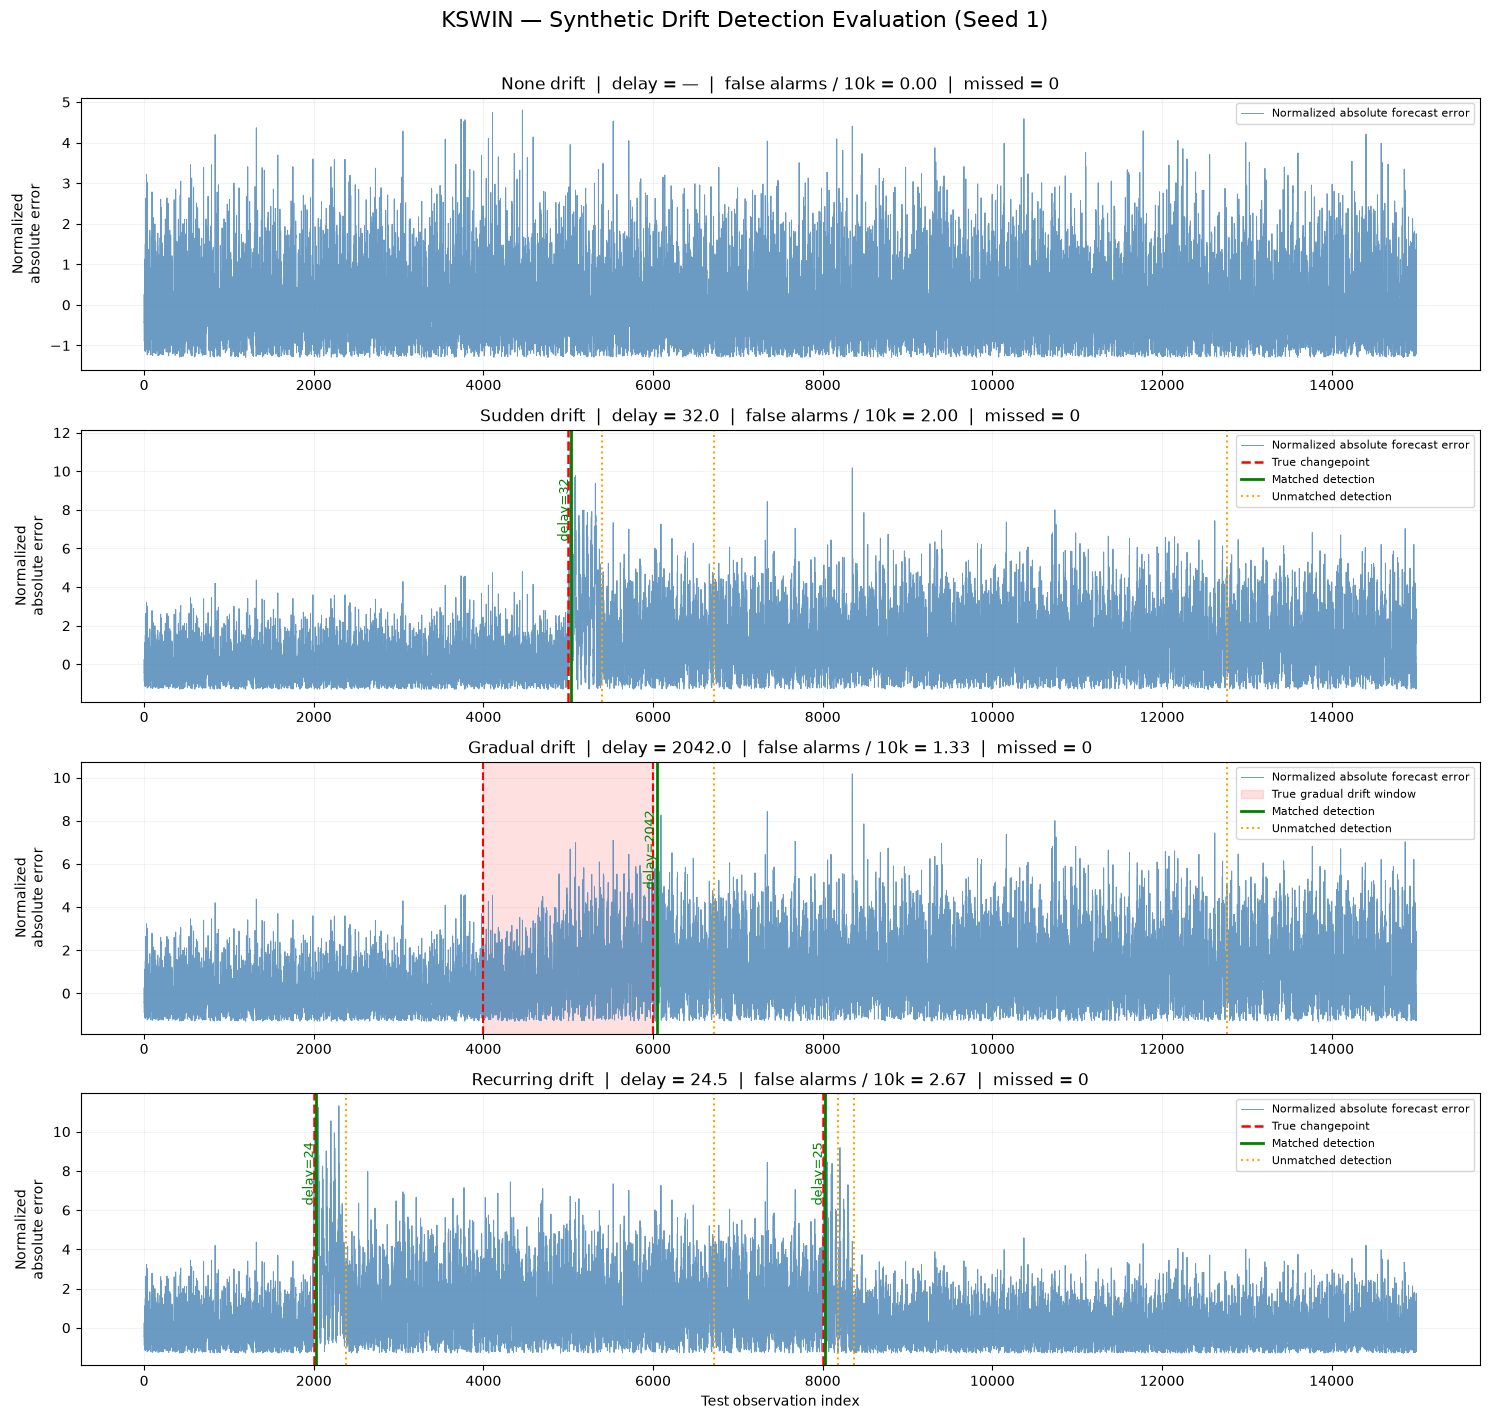

In [ ]:
plot_detector_evaluation(
    detector_name="KSWIN",
    detector_func=detectors.run_kswin,
    detector_config={
        "alpha": 0.00005,
        "window_size": 140,
        "stat_size": 70,
        "seed": 12,
    },
    seed=1,
)

# Final Detector Comparison and Analysis

All three detectors were evaluated under the same experimental protocol using the calibration-normalized absolute forecast-error stream from the frozen Gradient Boosting forecaster. The final configurations were fixed before this comparison and evaluated across the same four synthetic scenarios and five seeds.

### Final Configurations

- **ADWIN:** `delta = 0.0001`
- **Page-Hinkley:** `threshold = 209`, `alpha = 0.999`, `delta = 0.005`, `min_instances = 30`
- **KSWIN:** `alpha = 0.00005`, `window_size = 140`, `stat_size = 70`, internal `seed = 12`

All three final configurations produced **zero detections across all five no-drift seeds**, satisfying the negative-control requirement.

### Comparative Performance

**ADWIN provided the strongest overall balance across the evaluated synthetic scenarios.** It achieved the shortest mean detection delay for sudden drift (23.0 observations), gradual drift (600.6), and recurring drift (29.4), while producing relatively low false-alarm rates and no missed drift events across the five evaluation seeds.

**Page-Hinkley was more conservative than ADWIN.** It produced the lowest sudden-drift false-alarm rate (0.93 per 10,000 observations) and maintained relatively low false-alarm rates overall. However, its detection delays were longer than ADWIN for all three drift types, and one recurring-drift event was missed across the five seeds.

**KSWIN remained effective for sudden and recurring drift but showed the clearest sensitivity–false-alarm trade-off.** Its final configuration detected all sudden and recurring events with mean delays of 33.4 and 38.5 observations respectively. However, it produced the highest false-alarm rates and showed substantially weaker gradual-drift performance, with a mean delay of 1561.5 observations and one missed gradual event.

### Interpretation

The results demonstrate that detector performance depends strongly on drift type and configuration. No detector should be interpreted as universally optimal from this synthetic benchmark alone.

Under the adopted evaluation criteria, **ADWIN is the strongest overall performer**, combining comparatively short detection delays, complete drift coverage, and moderate false-alarm rates. Page-Hinkley provides a more conservative alternative, while KSWIN demonstrates good sensitivity to abrupt and recurring changes but is less suitable for the gradual-drift pattern represented in this benchmark.

These results justify carrying the frozen detector configurations forward to the subsequent real-data evaluation. Performance on synthetic data should not be assumed to transfer directly to the AEMO stream, where true changepoints are not known.

______________________________________________